

# MODULE 53 — FREQUENCY DOMAIN & SPECTRAL ANALYSIS

So far, we've visualized audio as a waveform — amplitude changing over time. But there's a limitation: a waveform tells us how the signal changes, not directly which frequencies are present inside it.

For example, human speech contains multiple frequencies simultaneously. To understand those frequencies, we need to move from the time domain to the frequency domain.

This is where Fourier Transform, FFT, STFT, and spectrograms come in.

---

## 4.1 Time Domain vs Frequency Domain

Let's begin with the fundamental difference.

### 1. Time Domain

The time domain represents how an audio signal's amplitude changes over time.

It answers:

- When did a sound occur?
- How did its amplitude change?
- Where does speech begin and end?
- Where are the pauses?

Mathematically, a continuous-time signal is represented as:

$$
x(t)
$$

A discrete audio signal is represented as:

$$
x[n]
$$

Where:

- \(x\) = Audio signal.
- \(t\) = Continuous time.
- \(n\) = Sample index.

![Audio data representation](https://images.openai.com/static-rsc-4/7SYWnoQSL5Cb5sgqHn0J9mp4ENusPm6affI9DX0m9tClGqlVK02d7MidBoLyJAD4tCViFH2HkC_djy8U8nefZzCfjtPoDss7SEED9iAfqB5vTbb6IA4L4mBiW8_N59biHSgTuuVpG7DHi-kgym2pszIQ_nwpb3pueznNRs-iTaw?purpose=inline)

Source: [Scaler Topics](https://www.scaler.com/topics/pytorch/audio-data-pytorch/)

### 2. Frequency Domain

The frequency domain represents the frequency components contained in an audio signal.

It answers:

- Which frequencies are present?
- How strong is each frequency?
- Is the audio dominated by low or high frequencies?
- What frequency components make up a speech signal?

Instead of plotting amplitude against time, we examine magnitude against frequency.

![FFT frequency domain illustration](https://images.openai.com/static-rsc-4/N_3Mtcrz6wTzgQTdAWwA85oQPqhuQZTKlJ_9ykMFsMRGdQdvnV4AKWqPj6w2zruMpbwTtWFedCMuKLleWIZw9GUEjn1USnJSswRmOjPJy-zrnwG888w7HPxmXGBkmJzvhj1t4P0szaWBTQKDIlAU79FUpHwgApWqzQaUUdD0SrU?purpose=inline)

Source: [Jien Weng — FFT Explained](https://jienweng.github.io/notes/fft-sound-wave/)

### Comparison

| Time Domain | Frequency Domain |
|---|---|
| Amplitude vs Time | Magnitude vs Frequency |
| Shows signal changes over time | Shows frequency components |
| Helps identify pauses | Helps identify frequency content |
| Displays waveform | Displays frequency spectrum |
| Uses \(x(t)\) or \(x[n]\) | Uses \(X(f)\) or \(X[k]\) |

### Why do we need both?

Imagine recording someone speaking.

The waveform shows when the person speaks.

The frequency spectrum shows which frequency components are present in the recording.

Both provide different information about the same audio signal.

---

## 4.2 Fourier Transform (FT)

This is one of the most important mathematical concepts in signal processing.

### What is the Fourier Transform?

Fourier Transform is a mathematical operation that converts a signal from the time domain into the frequency domain.

The fundamental idea is that a complex signal can be represented as a combination of sinusoidal components with different frequencies, amplitudes, and phases.

For example, consider a signal containing:

- 100 Hz sine wave.
- 200 Hz sine wave.
- 400 Hz sine wave.

When these signals are added together, they create a more complex waveform.

Fourier Transform helps us identify the individual frequency components.

![Fourier decomposition](https://images.openai.com/static-rsc-4/0pcbGyW3nVi3k-ZCHkRdKdyTmROqDGx0ISLBGVNmDdVRwWugeI_IquHHbXzfcfJt_QycglDWVOKupQLZKF4YUtBath3WkGhpqKLBwkfUYc2Qpi8q2qaKBRgec8P8gsW5sobuaOQvgZ9XeoPqi_SgJ8T1N5I18omoWOkpLxCG3xw?purpose=inline)

Source: [Statistics and Machine Learning in Python](https://duchesnay.github.io/pystatsml/numerical_methods/time_series.html)

### Mathematical representation

The continuous Fourier Transform is:

$$
X(f)=\int_{-\infty}^{\infty}x(t)e^{-j2\pi ft}\,dt
$$

Where:

- \(x(t)\) = Original time-domain signal.
- \(X(f)\) = Frequency-domain representation.
- \(f\) = Frequency.
- \(j\) = Imaginary unit.
- \(e^{-j2\pi ft}\) = Complex sinusoidal basis function.

Don't worry if the equation looks complicated. Let's understand the intuition.

The Fourier Transform checks how much of each frequency component is present in the original signal.

The result is a complex-valued frequency representation containing both:

- Magnitude — strength of frequency components.
- Phase — phase information of frequency components.

### Example

Suppose our original signal is:

$$
x(t)=\sin(2\pi100t)+0.5\sin(2\pi200t)
$$

This signal contains:

| Frequency | Amplitude |
|---|---:|
| 100 Hz | 1.0 |
| 200 Hz | 0.5 |

After Fourier Transform, we should observe peaks corresponding to 100 Hz and 200 Hz.

![Fourier transform intuition](https://images.openai.com/static-rsc-4/rY5cxziClt7Pd7Qmz_YK9Ojy0S4FvsJOfUCDdysp8jnTejVSJHNhKODHlMdPwC1gigkobMieS-qASZQUAsMDXbc1xlaKNtFHvCpExSP_m7z8lye5sE7ejBTsAUvhDuGgdItYpKgPsmUHLJ2SJEFH1sx8qFLqvr2aUky-ouTnJDg?purpose=inline)

Source: [Zenn](https://zenn.dev/phykm/articles/a84e953b454507)

**Important:** Fourier Transform doesn't create new frequencies. It reveals the frequency components already present in the signal.

---

## 4.3 Discrete Fourier Transform (DFT)

In practical AI/ML applications, we work with digital audio represented by discrete samples.

Therefore, we need a discrete version of the Fourier Transform.

This is called the **Discrete Fourier Transform (DFT)**.

### What is DFT?

DFT converts a finite sequence of time-domain samples into a finite sequence of frequency-domain components.

Mathematical formula:

$$
X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N}
$$

Where:

- \(x[n]\) = Input audio samples.
- \(X[k]\) = Frequency-domain output.
- \(N\) = Total number of samples.
- \(n\) = Time-domain sample index.
- \(k\) = Frequency-bin index.

### Understanding frequency bins

DFT divides the frequency range into discrete frequency bins.

The frequency represented by bin \(k\) is:

$$
f_k=\frac{k f_s}{N}
$$

Where:

- \(f_s\) = Sampling rate.
- \(N\) = Number of samples.

The frequency resolution is:

$$
\Delta f=\frac{f_s}{N}
$$

### Example

Suppose:

- Sampling rate = 16,000 Hz.
- Number of samples = 1,600.

Then:

$$
\Delta f=\frac{16000}{1600}
$$

$$
\boxed{\Delta f=10\text{ Hz}}
$$

This means consecutive DFT bins are separated by 10 Hz.

For a real-valued signal, the unique non-negative frequency components extend from 0 Hz up to the Nyquist frequency:

$$
f_{\text{Nyquist}}=\frac{f_s}{2}
$$

For a 16 kHz signal:

$$
f_{\text{Nyquist}}=8000\text{ Hz}
$$

So the unique spectrum covers 0–8,000 Hz.

### Why is DFT important?

- Frequency analysis.
- Audio filtering.
- Noise analysis.
- Spectral feature extraction.
- Building spectrograms.

---

## 4.4 Fast Fourier Transform (FFT)

You may wonder:

If DFT already performs frequency conversion, why do we need FFT?

### What is FFT?

FFT is an efficient algorithm for computing the Discrete Fourier Transform.

The DFT definition requires approximately:

$$
O(N^2)
$$

operations using a straightforward implementation.

FFT algorithms can reduce this to approximately:

$$
O(N\log N)
$$

for commonly used transform sizes.

This makes FFT much faster for large audio signals.

![FFT algorithm](https://images.openai.com/static-rsc-4/LHCKuTXhycPYg4tNRqHIq-_9jhaj9fxySxWD5vopXu9kuAw0YgPw5mnBln693l-JwmfykheIFoY9M5tYQ-qtguPaGbZNSJr43XFJCPlxmrFHppkViQmUINmo4TByIfDXmy3o0vbHJ0bIi7OQi0-z-p_tXrrZ4PACBNUrFMLxRM0?purpose=inline)

Source: [SlideServe — FFT in Hardware and Software](https://www.slideserve.com/jena/fft-in-hardware-and-software)

### DFT vs FFT

| DFT | FFT |
|---|---|
| Mathematical transform | Efficient computational algorithm |
| Defines frequency conversion | Computes the DFT efficiently |
| Direct computation can be expensive | Much faster for large signals |
| Foundation of frequency analysis | Widely used in practical audio processing |

**Important:** FFT and DFT are not two different types of frequency transformations. FFT is an algorithm for computing DFT.

### Python implementation — DFT using NumPy FFT

Let's generate a signal containing two frequencies.

```python
import numpy as np
import matplotlib.pyplot as plt

# Parameters
sampling_rate = 16000
duration = 1

# Time axis
t = np.arange(
    int(sampling_rate * duration)
) / sampling_rate

# Generate two sine waves
signal = (
    np.sin(2 * np.pi * 100 * t)
    +
    0.5 * np.sin(2 * np.pi * 200 * t)
)

# Calculate FFT
fft_result = np.fft.fft(signal)

# Calculate magnitude
magnitude = np.abs(fft_result)

# Frequency axis
frequencies = np.fft.fftfreq(
    len(signal),
    d=1 / sampling_rate
)

# Keep positive frequencies
positive = frequencies >= 0

plt.figure(figsize=(12, 4))

plt.plot(
    frequencies[positive],
    magnitude[positive]
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Frequency Spectrum")

plt.xlim(0, 500)
plt.grid()
plt.show()
```

You should observe peaks around:

- 100 Hz.
- 200 Hz.

This is our first practical demonstration of frequency analysis! 🚀

---

## 4.5 Frequency Spectrum

After applying the Fourier Transform, we obtain a frequency-domain representation called the **frequency spectrum**.

It tells us which frequency components are present in an audio signal and how strong they are.

![Audio frequency spectrum](https://images.openai.com/static-rsc-4/v2_hFUt5uuOoUb14q8KDLNTZQfeJl72UXwZWlnjYcr-yMkjt5LHeQFo_AtN2yZ10OUyj9cVlvjh1Ikekmm3VVISmHXedb3VK-fcwEebOx5TVr_itWW7Vbu2Qa8QeoHr77WXpBmcn44bLzWPGPO0_8dNJkItLhhud1MXEURZF3dc?purpose=inline)

Source: [Audio Editor](https://www.audio-editor.online/blog/equalize-audio-online)

### Understanding the spectrum

Consider a signal containing three sine waves:

$$
x(t)=\sin(2\pi100t)+0.7\sin(2\pi200t)+0.3\sin(2\pi400t)
$$

Its frequency spectrum contains three major peaks:

| Frequency | Amplitude |
|---|---:|
| 100 Hz | 1.0 |
| 200 Hz | 0.7 |
| 400 Hz | 0.3 |

The horizontal axis represents frequency, while the vertical axis represents the strength of each frequency component.

### Important observations

- A peak at 100 Hz indicates a strong 100 Hz component.
- A peak at 200 Hz indicates a 200 Hz component.
- A peak at 400 Hz indicates a 400 Hz component.
- A broad distribution of frequencies indicates a more complex signal.

**In speech processing:** Human speech is made up of many frequency components. Its spectrum changes depending on the speaker, spoken sounds, and recording conditions.

---

## 4.6 Spectral Magnitude

The output of the DFT or FFT is generally complex-valued.

A complex number contains:

- Real part
- Imaginary part

We calculate its magnitude to understand the strength of each frequency component.

For a complex FFT result:

$$
X[k]=a+jb
$$

The magnitude is:

$$
|X[k]|=\sqrt{a^2+b^2}
$$

In Python:

```python
magnitude = np.abs(fft_result)
```

Here, `np.abs()` calculates the magnitude of each complex frequency component.

### Magnitude vs frequency

![Magnitude and frequency](https://images.openai.com/static-rsc-4/6eWxTZ8ruvoN0yrT9-BIOZ3yydDEpFrMLTvKLk-TnK5unuAbOXhiEFlE-Nx5Pvi_zW-qN-9wUGW2_jMKAsJV8TYpfSq8s49PJBS6s413bcINatc7S8EIoInmss04qG0EafAgmldsZPngKNOI4oozGkv2qyXE0aBxwLlR8Rk8Umk?purpose=inline)

Source: [TutorialsPoint — SciPy FFT](https://www.tutorialspoint.com/scipy/scipy_fast_fourier_transform.htm)

What does spectral magnitude tell us?

It tells us the relative strength of frequency components.

For example:

- Large magnitude → Strong frequency component.
- Small magnitude → Weak frequency component.
- Zero magnitude → No contribution at that frequency bin.

**Important:** Raw FFT magnitude depends on the number of samples and the scaling convention. When comparing amplitudes, we should use appropriate normalization.

### Normalized single-sided amplitude spectrum

For a real-valued signal, we often display only the positive-frequency half of the spectrum.

Here's a better version of our earlier FFT example that gives an approximately correct amplitude scale for bin-centred sine waves:

```python
import numpy as np
import matplotlib.pyplot as plt

sampling_rate = 16000
duration = 1

t = np.arange(
    int(sampling_rate * duration)
) / sampling_rate

signal = (
    np.sin(2 * np.pi * 100 * t)
    + 0.5 * np.sin(2 * np.pi * 200 * t)
)

N = len(signal)

fft_result = np.fft.rfft(signal)

magnitude = np.abs(fft_result) / N

# Single-sided amplitude correction
magnitude[1:-1] *= 2

frequencies = np.fft.rfftfreq(
    N,
    d=1 / sampling_rate
)

plt.figure(figsize=(12, 4))

plt.plot(frequencies, magnitude)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Single-Sided Amplitude Spectrum")

plt.xlim(0, 500)
plt.grid()
plt.show()
```

**Expected major peaks:**

- 100 Hz → approximately 1.0
- 200 Hz → approximately 0.5

---

## 4.7 Spectral Energy

Magnitude tells us the strength of a frequency component. Spectral energy tells us how much energy is associated with frequency components.

A commonly used quantity is the squared magnitude:

$$
P[k]=|X[k]|^2
$$

This is often called the power spectrum (with appropriate normalization depending on the definition).

For a discrete signal, total signal energy is:

$$
E=\sum_{n=0}^{N-1}|x[n]|^2
$$

Parseval's theorem connects the energy in the time domain and frequency domain.

For the unnormalized DFT convention used by NumPy:

$$
\sum_{n=0}^{N-1}|x[n]|^2
=
\frac{1}{N}\sum_{k=0}^{N-1}|X[k]|^2
$$

This tells us that the signal's energy can be understood in either domain.

### Python implementation

```python
# Time-domain energy
time_energy = np.sum(signal ** 2)

# Frequency-domain energy
frequency_energy = (
    np.sum(np.abs(fft_result) ** 2) / N
)

print("Time Domain Energy:", time_energy)
print("Frequency Domain Energy:", frequency_energy)
```

Both values should be approximately equal, allowing for numerical precision.

### Why is spectral energy useful in audio processing?

It helps us understand:

- Energy distribution across frequencies.
- Frequency characteristics of speech.
- Background noise.
- Audio intensity patterns.
- Differences between speech and non-speech signals.

Remember:

| Quantity | Formula | Meaning |
|---|---|---|
| Spectral magnitude | \(|X[k]|\) | Strength of frequency component |
| Spectral power | \(|X[k]|^2\) | Squared magnitude |
| Signal energy | \(\sum |x[n]|^2\) | Total energy of finite signal |

---

## 4.8 Why Fourier Transform Alone Is Not Enough for Speech

This is a very important concept.

Imagine someone says:

"Hello, how are you?"

The frequency content changes continuously as the person speaks.

A single Fourier Transform of the complete recording gives us an overall frequency representation.

But it doesn't tell us exactly when each frequency occurred.

For speech recognition, timing matters!

Consider:

- The frequency characteristics of "Hello".
- The frequency characteristics of "How".
- The frequency characteristics of "You".

We need a technique that examines frequency content over short intervals.

That technique is called the **Short-Time Fourier Transform (STFT)**.

![Spectrogram and STFT](https://images.openai.com/static-rsc-4/iUlMArt50KDAlCgVSiZBs7Fp7n6gO_cRFvJz-tCgoVmPFEFrm3ba45sLw8GwmfkpUpE4xlqj0bZa3LZv89SEDJgrAlD1rweMng9pUL5lS1SmME28-UQRYDHK0B8biMT9TLfcoZRqVmT2F8DVih_es73IIUma1-S5B70YqCs0W_Q?purpose=inline)

Source: [Introduction to Speech Processing — Aalto University](https://speechprocessingbook.aalto.fi/Representations/Spectrogram_and_the_STFT.html)

---

## 4.9 Short-Time Fourier Transform (STFT)

### What is STFT?

The Short-Time Fourier Transform analyzes a signal by dividing it into small, overlapping time segments and applying the Fourier Transform to each segment.

Instead of analyzing the entire audio recording at once, we analyze smaller portions.

This helps us understand how frequency content changes over time.

### How does STFT work?

Consider a 10-second speech recording.

The STFT process:

1. Divide the audio into short frames.
2. Apply a window function to each frame.
3. Calculate the FFT of each windowed frame.
4. Move to the next frame.
5. Repeat the process.
6. Combine the frequency information from all frames.

![STFT frame analysis](https://images.openai.com/static-rsc-4/fbVVuuS1ojNzeybq53ervnyvp0XNecBIur-8G6mGaNYSf1V4mjCpYbTKWotXoJ881XI369u04I8nZQV5IbjDWK1v4-rElZgiRAIFKmBtCRnp_PVk2RE4S3I_NoqCVbixiQn_077cYzAZ1mv5Qe-MiwMmhmwjS_C3Cj7Sj4_DOUg?purpose=inline)

Source: [John Hartquist](https://johnhartquist.com/resonators)

### STFT mathematical representation

One common discrete-time STFT definition is:

$$
X(m,k)=
\sum_{n=0}^{N-1}
x[n+mH]w[n]e^{-j2\pi kn/N}
$$

Where:

- \(x[n]\) = Original audio signal.
- \(m\) = Frame index.
- \(k\) = Frequency-bin index.
- \(N\) = Frame length / FFT size in this expression.
- \(H\) = Hop length.
- \(w[n]\) = Window function.

The output is a two-dimensional representation:

- One dimension represents time frames.
- The other dimension represents frequency bins.

Each cell contains a complex frequency value.

This is the foundation of the spectrogram.

### Important STFT parameters

| Parameter | Meaning |
|---|---|
| `n_fft` | FFT size |
| `win_length` | Length of the window |
| `hop_length` | Number of samples between consecutive frames |
| `window` | Window function applied to each frame |

Let's understand these individually.

---

## 4.10 Windowing

When we divide audio into small frames, we need to consider what happens at the boundaries.

A sudden cut at the beginning and end of a frame can introduce artificial frequency components.

This phenomenon is called **spectral leakage**.

### What is spectral leakage?

Spectral leakage occurs when the finite segment of a signal does not align appropriately with the periodic assumptions of the DFT.

The result is that energy from one frequency component spreads into neighbouring frequency bins.

![Spectral leakage](https://images.openai.com/static-rsc-4/JNa6s13lHzpN3VaTSODHGxUV9k1GRIMWiRnhnvQ41Izp1wCwWnS-fLxUVwl502VbTLxzJrFIl-aVL8FZMXwF5Nhv6ZcheRYcHoDeSNS6DDElFaXM-Z_Puomld4_7dtGMefVFEf0X6d47NYi-I8H1AhIzMW2J0MKzySqWRqspuIw?purpose=inline)

Source: [DSPRelated](https://www.dsprelated.com/showarticle/1433.php)

### What is windowing?

Windowing means multiplying each audio frame by a window function before applying the FFT.

This reduces the abrupt transitions at frame boundaries and can reduce spectral leakage.

Mathematically:

$$
x_w[n]=x[n]\times w[n]
$$

Where:

- \(x[n]\) = Original audio frame.
- \(w[n]\) = Window function.
- \(x_w[n]\) = Windowed audio frame.

### Common window functions

![Window functions](https://images.openai.com/static-rsc-4/XZIS8SrBqITU0218LKykvkjN44jiJPMCIjxpjwwt4AT5PqnZhbhzouSyVC6o5mhWx39z4_TPhPcEFYTRT7abEHjCh_TGD8MqBdNQV2V1NqAEazjSXyjhvPGxJvAVnwW23l8E1aulEzHhbZYtIuTQPWRQ_xTve4qx-P3zTFjbuFs?purpose=inline)

Source: [Journal of Semiconductors](https://www.jos.ac.cn/article/current)

| Window | Description |
|---|---|
| Rectangular | No tapering at the boundaries |
| Hann | Smoothly tapers both ends to zero |
| Hamming | Similar to Hann, with non-zero endpoint values |
| Blackman | Stronger sidelobe suppression, with a wider main lobe |

### Hann window

One commonly used window is the Hann window.

Its formula is:

$$
w[n]=0.5\left(1-\cos\left(\frac{2\pi n}{N-1}\right)\right)
$$

It reduces the abrupt boundaries of each frame.

In Python:

```python
import numpy as np
import matplotlib.pyplot as plt

N = 512

hann_window = np.hanning(N)

plt.figure(figsize=(10, 4))

plt.plot(hann_window)

plt.title("Hann Window")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")

plt.grid()
plt.show()
```

### Why do we use windowing in speech processing?

- Reduces spectral leakage.
- Improves frequency analysis.
- Produces more useful local frequency representations.
- Helps generate spectrograms.

**Important trade-off:** Windowing reduces leakage but also changes the spectral characteristics. Different windows provide different trade-offs between main-lobe width and sidelobe suppression.

---

## 4.11 Spectrogram

Now we've reached one of the most important visualizations in audio and speech processing! 🔥

### What is a spectrogram?

A spectrogram is a visual representation of how the frequency content of an audio signal changes over time.

It is generally calculated from the Short-Time Fourier Transform (STFT).

A spectrogram displays three dimensions:

1. Time — horizontal axis.
2. Frequency — vertical axis.
3. Magnitude or power — represented using colour intensity.

![Speech spectrogram](https://images.openai.com/static-rsc-4/zgyvJsDLzsJuhwayzukI8kH3U8pDaGgVExo9NLOFAIL6IjSlFQWdnNkz5VPslJPjVKGn3gUeMiDTxwhVCEv18yk5cfqPqBPayRBCUdN3aKFU3fx4DZXUQ8mowHlPmbedPa9EGMzXrDAsRuu6MkklyFR_D9Mw0DazwqQ6pAnBVBI?purpose=inline)

Source: [Geekflare — Speech Synthesis](https://geekflare.com/blog/speech-synthesis/)

### Understanding a spectrogram

Let's understand its components.

| Component | Represents |
|---|---|
| X-axis | Time (seconds) |
| Y-axis | Frequency (Hz) |
| Colour intensity | Spectral magnitude or power |

Typically:

- Brighter regions indicate stronger frequency components.
- Darker regions indicate weaker frequency components.
- Horizontal patterns can represent sustained frequency components.
- Changing patterns show how the frequency content evolves.

The exact colour meaning depends on the colour scale used.

### Waveform vs Spectrogram

![Waveform](https://images.openai.com/static-rsc-4/rYDikgl9RKl2EGCKixMikNPpVOAd_P9DuP60S4lslrbZaxkWg_1p4LzP9-YZkSNnjfHOcROzymvVhX-yM7HWWY0gdQahtzlvHHWQRopDSvYNmcnF7H6-CIgAk-HnHr3QLnfl0F9NVX9x5Gt81xId_pahToVbz3PYqkcjEHGBOhM?purpose=inline)

**Waveform**

- Amplitude vs time.
- Shows signal strength.
- Helps identify pauses and clipping.

![Spectrogram](https://images.openai.com/static-rsc-4/VXilE3fe5sC1vs93EQ5F3OPBkcGYMFKFuGwLgec7_AYhplh7uybqt0_dwaFUExqymNbt1fl-AaIKtkJ6D5WnCMJZq2PF_mITHXiXWL7jb6MhMM18ydO9VTSZgnCYWlzZe_V2xAgGbxVRte3-OQ5zi6VYg6SutwZOTmcX15xhPYs?purpose=inline)

**Spectrogram**

- Frequency vs time.
- Shows frequency distribution.
- Helps analyze speech characteristics.

### Why is a spectrogram useful for speech recognition?

Human speech contains different sound patterns.

For example:

- Vowels generally contain prominent resonant frequency bands called formants.
- Consonants can contain bursts, transitions, and noise-like frequency patterns.
- Voiced sounds often show harmonic structures.
- Unvoiced sounds often contain broadband noise-like energy.

A spectrogram helps us visualize these patterns.

### Magnitude spectrogram vs Power spectrogram

There are two commonly used forms.

**1. Magnitude spectrogram**

$$
S(m,k)=|X(m,k)|
$$

It represents the magnitude of the STFT.

**2. Power spectrogram**

$$
P(m,k)=|X(m,k)|^2
$$

It represents the squared magnitude of the STFT.

Both are useful, but they represent different quantities.

### Why use decibels (dB)?

Audio signals can contain a very large range of magnitudes.

Displaying raw magnitude values can make weaker frequency components difficult to see.

Therefore, we often convert the spectrogram into a logarithmic decibel scale.

For magnitude:

$$
S_{dB}=20\log_{10}\left(\frac{|X|}{X_{\text{ref}}}\right)
$$

For power:

$$
P_{dB}=10\log_{10}\left(\frac{P}{P_{\text{ref}}}\right)
$$

Where the reference value determines the zero-decibel level.

In Librosa, we can use:

```python
S_db = librosa.amplitude_to_db(
    np.abs(stft_result),
    ref=np.max
)
```

Here, the maximum magnitude becomes approximately 0 dB, and weaker magnitudes are displayed as negative dB values.

---

## 4.12 Understanding STFT Parameters in Practice

Before building our spectrogram, let's understand three parameters that strongly affect the output.

### 1. FFT Size (`n_fft`)

This determines the number of points used for each FFT frame.

For a sampling rate of 16 kHz:

| FFT size | Frequency-bin spacing |
|---:|---:|
| 256 | 62.5 Hz |
| 512 | 31.25 Hz |
| 1024 | 15.625 Hz |
| 2048 | 7.8125 Hz |

Frequency-bin spacing is:

$$
\Delta f=\frac{f_s}{N_{\text{FFT}}}
$$

Larger FFT sizes provide finer frequency-bin spacing, but use a longer analysis frame.

### 2. Hop Length (`hop_length`)

Hop length determines how many samples we move forward before analyzing the next frame.

For example:

- FFT size = 1024.
- Hop length = 256.

The overlap between consecutive frames is:

$$
\text{Overlap}=1024-256=768
$$

Overlap percentage:

$$
\frac{768}{1024}\times100=75\%
$$

![STFT hop length and overlap](https://images.openai.com/static-rsc-4/gZ1nLltAGoT5XY_F5Z3z2DtEJIhzRvulDbbAydYd9Ko7jK_vFr7-b-XNBcfFZlbCn48no3-sbPBCK6CbSfn4K7b5DL6DNXW0t3G8hCsdhAwcEKQiIzwGcLK2X-D7CJE5RuRofg1rPxhwpaFuqM6dxeoBCHaDJCOWN8g-t2u52DM?purpose=inline)

Source: [Applied Sciences — MDPI](https://www.mdpi.com/2076-3417/14/4/1553)

A smaller hop length produces more frequent time measurements.

### 3. Window Length (`win_length`)

Window length determines how many actual audio samples are multiplied by the window function.

It is usually equal to `n_fft` in common configurations.

If `win_length` is smaller than `n_fft`, the windowed frame is padded to the FFT size.

### Time-frequency trade-off

This is an important concept.

| Larger analysis window | Smaller analysis window |
|---|---|
| Better frequency resolution | Better time resolution |
| Less precise localization of short events | More precise localization of short events |
| Useful for resolving nearby frequencies | Useful for tracking rapid changes |

You cannot achieve arbitrarily high time and frequency resolution simultaneously.

This is known as the **time-frequency resolution trade-off**.

For speech analysis, we commonly use relatively short frames because speech changes over time.

---

## 4.13 Practical Lab — Generate a Spectrogram Using Python

Now let's implement everything.

We'll use `Librosa` and `Matplotlib` to:

1. Load a speech recording.
2. Generate its waveform.
3. Calculate its STFT.
4. Extract spectral magnitude.
5. Convert magnitude into decibels.
6. Display its spectrogram.

### Step 1 — Import libraries

```python
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
```

### Step 2 — Load an audio file

```python
audio, sample_rate = librosa.load(
    "speech.wav",
    sr=None,
    mono=True
)

print("Sampling Rate:", sample_rate)
print("Number of Samples:", len(audio))
print("Duration:", len(audio) / sample_rate)
```

### Step 3 — Visualize the waveform

```python
plt.figure(figsize=(14, 4))

librosa.display.waveshow(
    audio,
    sr=sample_rate
)

plt.title("Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.show()
```

### Step 4 — Calculate STFT

```python
n_fft = 1024
hop_length = 256

stft_result = librosa.stft(
    audio,
    n_fft=n_fft,
    hop_length=hop_length,
    win_length=n_fft,
    window="hann"
)
```

Here:

- `n_fft=1024` → FFT size.
- `hop_length=256` → Movement between consecutive frames.
- `win_length=1024` → Window length.
- `window="hann"` → Hann window.

The output is a complex-valued matrix.

Its dimensions are approximately:

$$
\left(
\frac{n_{\text{fft}}}{2}+1,
\text{Number of frames}
\right)
$$

Each column represents one time frame, and each row represents a frequency bin.

### Step 5 — Calculate spectral magnitude

```python
magnitude = np.abs(stft_result)

print("STFT Shape:", stft_result.shape)
print("Magnitude Shape:", magnitude.shape)
```

This extracts the magnitude from the complex STFT output.

### Step 6 — Convert magnitude into decibels

```python
spectrogram_db = librosa.amplitude_to_db(
    magnitude,
    ref=np.max
)
```

This gives us a logarithmic representation that makes weaker frequency components easier to inspect.

### Step 7 — Visualize the spectrogram

```python
plt.figure(figsize=(14, 5))

librosa.display.specshow(
    spectrogram_db,
    sr=sample_rate,
    hop_length=hop_length,
    x_axis="time",
    y_axis="hz",
    cmap="magma"
)

plt.colorbar(
    format="%+2.0f dB"
)

plt.title("Speech Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()
```

![Speech spectral representation](https://images.openai.com/static-rsc-4/QIFT6fdGXegoJltiTm9B7F1cPdVol5Cc3fnwHXypKeBSRclzKatiAQEOy0lutvkuICdRXzIpvv4SLrllKjSrVve5z659DCnxURWgNG7GpK0yzMCepNsxuSvIEMPVioRNRnHUr-p9JW2VGb9MboXy0GUiCxe66Y50TbScc_bUMxA?purpose=inline)

Source: [Source-Filter Representation of Speech](https://samsad35.github.io/site-sfvae/)

### What should you observe?

When you run this using a speech recording, look for:

- Frequency patterns changing over time.
- Stronger and weaker frequency regions.
- Harmonic structures in voiced speech.
- Noise-like patterns in unvoiced speech.
- Different spectral structures across different spoken sounds.

Try changing `n_fft` and `hop_length` and observe how the spectrogram changes.

---

## 4.14 Complete Visualization — Waveform vs Spectrogram

Let's combine both visualizations into one figure.

This is a very useful diagnostic plot when working with speech datasets.

```python
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

# Load audio
audio, sample_rate = librosa.load(
    "speech.wav",
    sr=None,
    mono=True
)

# STFT parameters
n_fft = 1024
hop_length = 256

# Calculate STFT
D = librosa.stft(
    audio,
    n_fft=n_fft,
    hop_length=hop_length,
    win_length=n_fft,
    window="hann"
)

# Convert to dB
S_db = librosa.amplitude_to_db(
    np.abs(D),
    ref=np.max
)

# Create figure
fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 9)
)

# Waveform
librosa.display.waveshow(
    audio,
    sr=sample_rate,
    ax=axes[0]
)

axes[0].set_title("Waveform")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude")

# Spectrogram
img = librosa.display.specshow(
    S_db,
    sr=sample_rate,
    hop_length=hop_length,
    x_axis="time",
    y_axis="hz",
    cmap="magma",
    ax=axes[1]
)

axes[1].set_title("Spectrogram")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Frequency (Hz)")

fig.colorbar(
    img,
    ax=axes[1],
    format="%+2.0f dB"
)

plt.tight_layout()
plt.show()
```

### What have we achieved?

We can now examine the same recording in two different ways:

- Waveform → How amplitude changes over time.
- Spectrogram → How frequency content changes over time.

This is a foundation for understanding Mel Spectrograms and MFCCs, which we'll encounter in the next stages of audio feature extraction.

---

## 4.15 Important Differences — Quick Revision

| Concept | Meaning |
|---|---|
| Time Domain | Amplitude changes over time |
| Frequency Domain | Frequency components of a signal |
| Fourier Transform | Converts time-domain representation into frequency domain |
| DFT | Fourier Transform for finite discrete sequences |
| FFT | Efficient algorithm for calculating DFT |
| Frequency Spectrum | Frequency components and their strengths |
| Spectral Magnitude | Magnitude of frequency components |
| Spectral Energy | Energy distribution across frequency components |
| STFT | Frequency analysis over short time frames |
| Windowing | Reduces boundary discontinuities and spectral leakage |
| Spectrogram | Frequency content visualized over time |

### The complete relationship

```text
Raw Audio Signal
       ↓
Digital samples
       ↓
Divide into Frames
       ↓
Short-time segments
       ↓
Windowing
       ↓
Hann / Hamming
       ↓
FFT
       ↓
Frequency analysis of each frame
       ↓
STFT Matrix
       ↓
Frequency × Time
       ↓
Spectrogram
       ↓
Visual representation of spectral magnitude or power
```

---


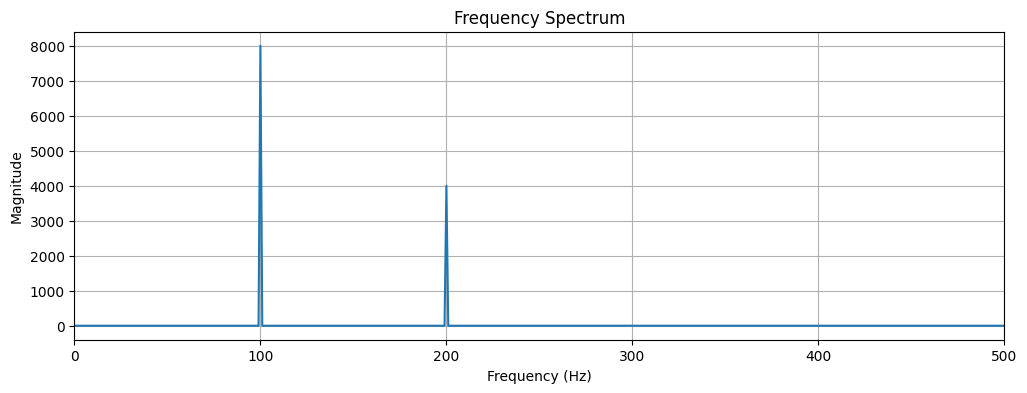

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
sampling_rate = 16000
duration = 1

# Time axis
t = np.arange(
    int(sampling_rate * duration)
) / sampling_rate

# Generate two sine waves
signal = (
    np.sin(2 * np.pi * 100 * t)
    +
    0.5 * np.sin(2 * np.pi * 200 * t)
)

# Calculate FFT
fft_result = np.fft.fft(signal)

# Calculate magnitude
magnitude = np.abs(fft_result)

# Frequency axis
frequencies = np.fft.fftfreq(
    len(signal),
    d=1 / sampling_rate
)

# Keep positive frequencies
positive = frequencies >= 0

plt.figure(figsize=(12, 4))

plt.plot(
    frequencies[positive],
    magnitude[positive]
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Frequency Spectrum")

plt.xlim(0, 500)
plt.grid()

plt.show()

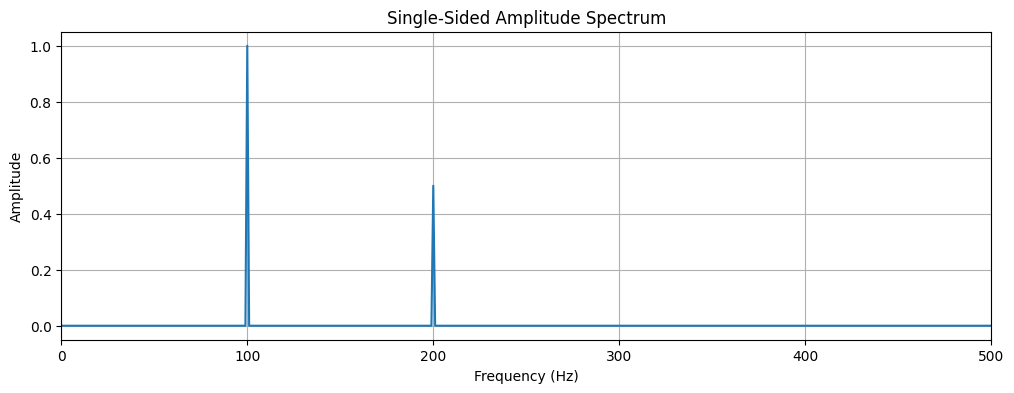

In [2]:
# Normalized single-sided amplitude spectrum


sampling_rate = 16000
duration = 1

t = np.arange(
    int(sampling_rate * duration)
) / sampling_rate

signal = (
    np.sin(2 * np.pi * 100 * t)
    + 0.5 * np.sin(2 * np.pi * 200 * t)
)

N = len(signal)

fft_result = np.fft.rfft(signal)

magnitude = np.abs(fft_result) / N

# Single-sided amplitude correction
magnitude[1:-1] *= 2

frequencies = np.fft.rfftfreq(
    N,
    d=1 / sampling_rate
)

plt.figure(figsize=(12, 4))

plt.plot(frequencies, magnitude)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Single-Sided Amplitude Spectrum")

plt.xlim(0, 500)
plt.grid()

plt.show()

In [3]:
# Spectral Energy

# Time-domain energy
time_energy = np.sum(signal ** 2)

# Frequency-domain energy
frequency_energy = (
    np.sum(np.abs(fft_result) ** 2) / N
)

print("Time Domain Energy:", time_energy)

print("Frequency Domain Energy:", frequency_energy)

Time Domain Energy: 10000.0
Frequency Domain Energy: 5000.0


In [4]:
import librosa
import librosa.display

audio, sample_rate = librosa.load(
    "example.mp3",
    sr=None,
    mono=True
)

print("Sampling Rate:", sample_rate)
print("Number of Samples:", len(audio))
print("Duration:", len(audio) / sample_rate)

Sampling Rate: 44100
Number of Samples: 122112
Duration: 2.7689795918367346


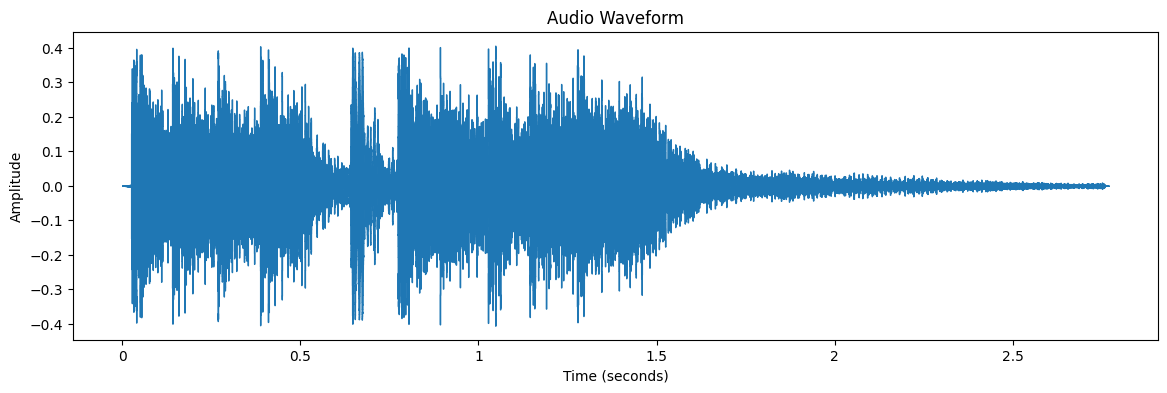

In [5]:
plt.figure(figsize=(14, 4))

librosa.display.waveshow(
    audio,
    sr=sample_rate
)

plt.title("Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.show()

STFT Shape: (513, 478)
Magnitude Shape: (513, 478)


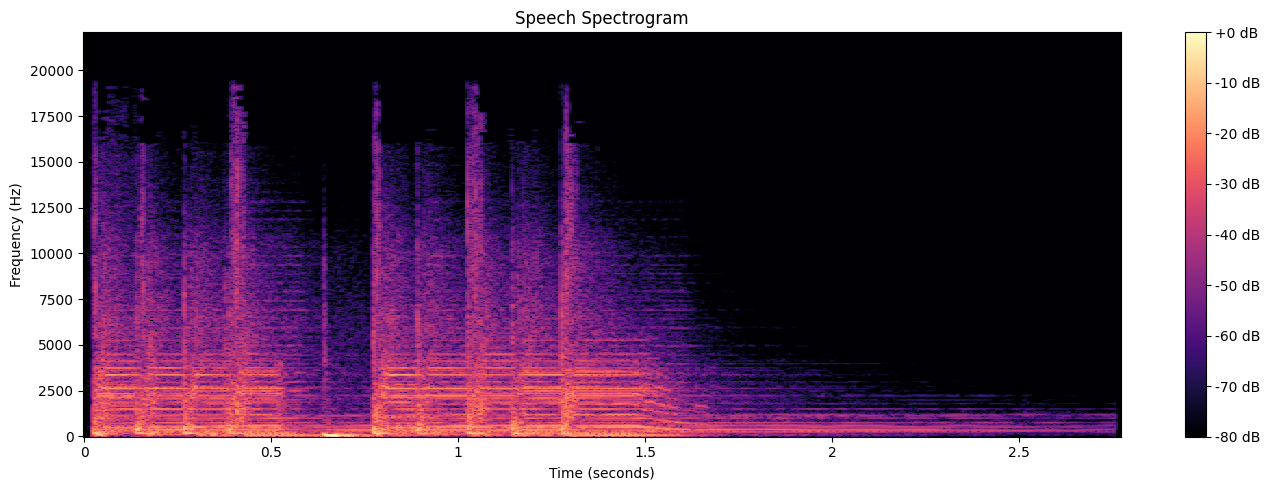

In [6]:
n_fft = 1024
hop_length = 256

stft_result = librosa.stft(
    audio,
    n_fft=n_fft,
    hop_length=hop_length,
    win_length=n_fft,
    window="hann"
)

magnitude = np.abs(stft_result)

print("STFT Shape:", stft_result.shape)

print("Magnitude Shape:", magnitude.shape)

spectrogram_db = librosa.amplitude_to_db(
    magnitude,
    ref=np.max
)

plt.figure(figsize=(14, 5))

librosa.display.specshow(
    spectrogram_db,
    sr=sample_rate,
    hop_length=hop_length,
    x_axis="time",
    y_axis="hz",
    cmap="magma"
)

plt.colorbar(
    format="%+2.0f dB"
)

plt.title("Speech Spectrogram")

plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()